# Домашняя работа №1. Диагностика A/B-эксперимента

Проверяем распределение пользователей между группами, баланс активности до эксперимента и частоту ошибок загрузки. Основная метрика — конверсия. Единица анализа — пользователь. Плановое соотношение групп — 50/50. Для каждой диагностической проверки используем уровень значимости 0,05.

Для повторного запуска положите `experiment_data.csv` в рабочую папку ноутбука. В Colab загрузите CSV через панель «Файлы» в `/content`. Если файла нет, ячейка ниже один раз создаст его с сохранённым seed.

In [1]:
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATA_PATH = Path("experiment_data.csv")
MY_SEED = 2507407
ALPHA = 0.05
GROUPS = ["control", "test"]
COLORS = ["#22577A", "#B64D35"]

## Генерация данных

Seed выбран случайно один раз. До генерации я сузил диапазон числа пользователей с 1000–9999 до 9500–9999. Это повышает мощность проверки редкой ошибки (1% против 2%). Остальные параметры исходного генератора сохранены.

В исходном коде назначение 40/60 перезаписывается назначением по `pre_activity`. Первый случайный вызов сохранён для воспроизводимости генератора. Фактическая доля test определяется средней вероятностью назначения по активности. Один механизм назначения создаёт два диагностических признака: отклонение от 50/50 и зависимость группы от активности.

В коде активность генерируется из экспоненциального распределения с последующим округлением вниз до целого.

In [2]:
def generate_experiment(seed):
    rng = np.random.RandomState(seed)
    n_users = rng.randint(9500, 10000)
    pre_activity = rng.exponential(scale=10, size=n_users).astype(int)
    activity_scaled = pre_activity / pre_activity.max()

    # Сохраняем первый случайный вызов из условия. Его результат перезаписывается.
    variant = rng.choice(GROUPS, size=n_users, p=[0.4, 0.6])
    prob_test = 0.4 + 0.3 * activity_scaled
    variant = np.where(rng.random(n_users) < prob_test, "test", "control")

    error_flag = np.zeros(n_users)
    is_control = variant == "control"
    is_test = variant == "test"
    error_flag[is_control] = rng.binomial(1, 0.01, is_control.sum())
    error_flag[is_test] = rng.binomial(1, 0.02, is_test.sum())

    conversion_prob = 0.05 + 0.01 * activity_scaled
    converted = rng.binomial(1, conversion_prob, n_users)
    start_date = pd.Timestamp("2026-05-01")
    dates = start_date + pd.to_timedelta(rng.randint(0, 14, size=n_users), unit="D")
    return pd.DataFrame({
        "user_id": np.arange(n_users),
        "variant": variant,
        "converted": converted,
        "error_flag": error_flag,
        "pre_activity": pre_activity,
        "date": dates,
    })


if DATA_PATH.exists():
    print(f"Используем готовый {DATA_PATH.name}")
else:
    generate_experiment(MY_SEED).to_csv(DATA_PATH, index=False, lineterminator="\n")
    print(f"Создан {DATA_PATH.name}")

print(f"Seed: {MY_SEED}")
print(f"SHA-256: {sha256(DATA_PATH.read_bytes()).hexdigest()}")

Используем готовый experiment_data.csv
Seed: 2507407
SHA-256: 545e9c250df8128c6e593312c4e7aa06111c547d6de3268a6821e551f71a1648


## 1. Загрузка и описание выборки

Проверяем схему, пропуски, уникальность пользователей и допустимые значения метрик. Даты проверяем при загрузке. Временные тренды в этой работе не анализируем.

In [3]:
def format_columns(table, formats):
    formatted = table.copy()
    for column, pattern in formats.items():
        formatted[column] = table[column].map(pattern.format)
    return formatted


df = pd.read_csv(DATA_PATH)
required = {"user_id", "variant", "converted", "error_flag", "pre_activity", "date"}
if not required.issubset(df.columns):
    raise ValueError(f"Отсутствуют столбцы: {sorted(required - set(df.columns))}")
if df[list(required)].isna().any().any() or not df["user_id"].is_unique:
    raise ValueError("В обязательных полях есть пропуски или user_id повторяется.")
if set(df["variant"].unique()) != set(GROUPS):
    raise ValueError("Ожидаются ровно две непустые группы: control и test.")
for column in ["converted", "error_flag"]:
    if not df[column].isin([0, 1]).all():
        raise ValueError(f"{column} должен быть бинарным.")
activity = pd.to_numeric(df["pre_activity"], errors="raise")
if not np.isfinite(activity).all() or activity.lt(0).any():
    raise ValueError("pre_activity должна быть конечной и неотрицательной.")
df["pre_activity"] = activity
df["date"] = pd.to_datetime(df["date"], errors="raise")

summary = df.groupby("variant").agg(
    users=("user_id", "size"),
    conversions=("converted", "sum"),
    errors=("error_flag", "sum"),
    mean_activity=("pre_activity", "mean"),
    median_activity=("pre_activity", "median"),
).reindex(GROUPS).astype({"conversions": int, "errors": int})
summary["sample_share"] = summary["users"] / len(df)
summary["conversion_rate"] = summary["conversions"] / summary["users"]
summary["error_rate"] = summary["errors"] / summary["users"]

print(f"Пользователей: {len(df):,} · Столбцов: {df.shape[1]}")
print(f"Даты: {df['date'].min():%Y-%m-%d} — {df['date'].max():%Y-%m-%d}")
display(format_columns(summary, {
    "mean_activity": "{:.2f}", "median_activity": "{:.0f}",
    "sample_share": "{:.2%}", "conversion_rate": "{:.2%}", "error_rate": "{:.2%}",
}))

Пользователей: 9,948 · Столбцов: 6
Даты: 2026-05-01 — 2026-05-14


,users,conversions,errors,mean_activity,median_activity,sample_share,conversion_rate,error_rate
variant,,,,,,,,
control,5664,278,57,8.89,6,56.94%,4.91%,1.01%
test,4284,230,79,10.23,7,43.06%,5.37%,1.84%


## 2. SRM

Критерий согласия Пирсона сравнивает наблюдаемые размеры групп с ожидаемыми при распределении 50/50. Нулевая гипотеза — обеим группам соответствует по половине случайных назначений.

In [4]:
expected = np.full(len(GROUPS), len(df) / len(GROUPS))
srm = stats.chisquare(summary["users"].to_numpy(), f_exp=expected)
srm_warning = srm.pvalue < ALPHA

display(pd.DataFrame({"Наблюдалось": summary["users"], "Ожидалось": expected}))
print(f"χ² = {srm.statistic:.3f}, df = 1, p = {srm.pvalue:.3g}")
print("SRM обнаружен" if srm_warning else "SRM: порог значимости не достигнут")

χ² = 191.435, df = 1, p = 1.55e-43
SRM обнаружен


,Наблюдалось,Ожидалось
variant,,
control,5664,4974.0
test,4284,4974.0


## 3. Баланс ковариаты `pre_activity`

Для правосторонне скошенной активности используем двусторонний U-тест Манна–Уитни. Проверку интерпретируем как различие распределений по рангам. Средние и медианы показывают направление различия. Для сравнения с бонусной корректировкой также считаем стандартизованную разность средних (SMD).

In [5]:
control = df.loc[df["variant"].eq("control")]
test = df.loc[df["variant"].eq("test")]
u_result = stats.mannwhitneyu(
    test["pre_activity"], control["pre_activity"], alternative="two-sided",
)
activity_warning = u_result.pvalue < ALPHA
smd_scale = np.sqrt(
    (test["pre_activity"].var(ddof=0) + control["pre_activity"].var(ddof=0)) / 2
)
raw_smd = (
    (summary.loc["test", "mean_activity"] - summary.loc["control", "mean_activity"]) / smd_scale
    if smd_scale > 0 else 0.0
)

print(f"U для test = {u_result.statistic:,.0f}, p = {u_result.pvalue:.3g}")
print(f"SMD (test − control) = {raw_smd:+.3f}")
print(
    "Дисбаланс по pre_activity — возможен confounder"
    if activity_warning else "Баланс pre_activity: порог значимости не достигнут"
)

U для test = 12,883,390, p = 1.13e-07
SMD (test − control) = +0.134
Дисбаланс по pre_activity — возможен confounder


## 4. Guardrail `error_flag`

Для редких ошибок используем точный критерий Фишера. Как правило остановки для этой работы выбираем одностороннюю проверку роста частоты ошибок в test при `p < 0.05`. График показывает 95%-е интервалы Уилсона для частот в отдельных группах.

In [6]:
def binary_counts(metric):
    # Строки: test, control. Столбцы: событие, отсутствие события.
    successes = summary.loc[["test", "control"], metric].to_numpy()
    totals = summary.loc[["test", "control"], "users"].to_numpy()
    return np.column_stack((successes, totals - successes))


error_table = binary_counts("errors")
guardrail = stats.fisher_exact(error_table, alternative="greater")
guardrail_warning = guardrail.pvalue < ALPHA
error_delta = summary.loc["test", "error_rate"] - summary.loc["control", "error_rate"]
print(f"Control: {summary.loc['control', 'error_rate']:.2%}")
print(f"Test: {summary.loc['test', 'error_rate']:.2%}")
print(f"Test − control: {100 * error_delta:+.2f} п.п.")
print(f"Односторонний p по Фишеру = {guardrail.pvalue:.3g}")
print(
    "Guardrail: частота ошибок в test статистически значимо выше"
    if guardrail_warning else "Guardrail: порог значимости для роста ошибок не достигнут"
)

Control: 1.01%
Test: 1.84%
Test − control: +0.84 п.п.
Односторонний p по Фишеру = 0.000275
Guardrail: частота ошибок в test статистически значимо выше


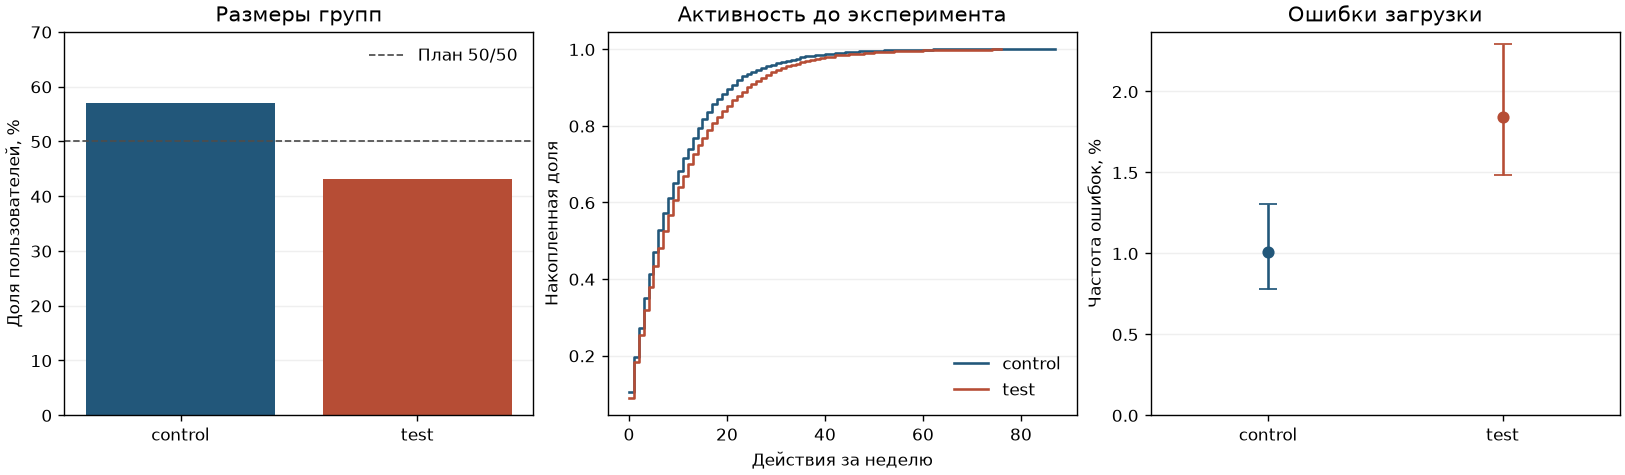

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")

axes[0].bar(GROUPS, 100 * summary["sample_share"], color=COLORS)
axes[0].axhline(50, color="0.3", ls="--", lw=1, label="План 50/50")
axes[0].set(title="Размеры групп", ylabel="Доля пользователей, %", ylim=(0, 70))
axes[0].legend(frameon=False)

for group, color in zip(GROUPS, COLORS):
    values, counts = np.unique(df.loc[df["variant"].eq(group), "pre_activity"], return_counts=True)
    axes[1].step(values, counts.cumsum() / counts.sum(), where="post", label=group, color=color)
axes[1].set(title="Активность до эксперимента", xlabel="Действия за неделю", ylabel="Накопленная доля")
axes[1].legend(frameon=False, loc="lower right")

for position, (group, color) in enumerate(zip(GROUPS, COLORS)):
    row = summary.loc[group]
    interval = stats.binomtest(int(row["errors"]), int(row["users"])).proportion_ci(method="wilson")
    rate = row["error_rate"]
    axes[2].errorbar(
        position, 100 * rate,
        yerr=[[100 * (rate - interval.low)], [100 * (interval.high - rate)]],
        fmt="o", capsize=5, color=color,
    )
axes[2].set(title="Ошибки загрузки", ylabel="Частота ошибок, %", xticks=[0, 1], xticklabels=GROUPS)
axes[2].set_xlim(-0.5, 1.5)
axes[2].set_ylim(bottom=0)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.show()

## 5. Решение о валидности

Срабатывание любой проверки блокирует тест основной метрики. При прохождении проверок сравниваем доли конверсии двусторонним точным тестом Фишера при том же пороге 0,05.

In [8]:
warnings = {
    "SRM": srm_warning,
    "Дисбаланс pre_activity": activity_warning,
    "Рост частоты ошибок": guardrail_warning,
}
failed_checks = [label for label, triggered in warnings.items() if triggered]

if failed_checks:
    print("Сработали проверки: " + ", ".join(failed_checks))
    print("Эксперимент не валиден")
    print("Остановить тест, исправить ошибки, перезапустить")
else:
    conversion = stats.fisher_exact(binary_counts("conversions"), alternative="two-sided")
    delta = summary.loc["test", "conversion_rate"] - summary.loc["control", "conversion_rate"]
    print(f"Конверсия, test − control: {100 * delta:+.2f} п.п., p = {conversion.pvalue:.3g}")
    if conversion.pvalue < ALPHA:
        print("Различие в конверсии статистически значимо.")
    else:
        print("Статистических оснований утверждать, что конверсии различаются, недостаточно.")

Сработали проверки: SRM, Дисбаланс pre_activity, Рост частоты ошибок
Эксперимент не валиден
Остановить тест, исправить ошибки, перезапустить


## 6. Бонус. Взвешивание по вероятности назначения

В учебном генераторе известна вероятность назначения `p(test | pre_activity)`. Для test используем вес `1/p`, для control — `1/(1 − p)`. Нормируем веса внутри каждой группы при расчёте средних, чтобы приблизить обе группы к распределению активности всей выборки. Для SMD сохраняем исходный масштаб. Сравниваем баланс, конверсию и ошибки до и после взвешивания. В расчёт входят все пользователи.

In [9]:
prob_test = 0.4 + 0.3 * df["pre_activity"] / df["pre_activity"].max()
assigned_prob = np.where(df["variant"].eq("test"), prob_test, 1 - prob_test)
weighted_df = df.assign(weight=1 / assigned_prob)
weighted_rows = []
for group in GROUPS:
    sample = weighted_df.loc[weighted_df["variant"].eq(group)]
    weights = sample["weight"].to_numpy()
    weighted_rows.append({
        "variant": group,
        "mean_activity": np.average(sample["pre_activity"], weights=weights),
        "conversion_rate": np.average(sample["converted"], weights=weights),
        "error_rate": np.average(sample["error_flag"], weights=weights),
        "effective_n": weights.sum() ** 2 / (weights ** 2).sum(),
    })
weighted = pd.DataFrame(weighted_rows).set_index("variant")
weighted_smd = (
    (weighted.loc["test", "mean_activity"] - weighted.loc["control", "mean_activity"]) / smd_scale
    if smd_scale > 0 else 0.0
)

comparison = pd.concat({
    "До взвешивания": summary.assign(effective_n=summary["users"])[weighted.columns],
    "После взвешивания": weighted,
})
display(format_columns(comparison, {
    "mean_activity": "{:.2f}", "conversion_rate": "{:.3%}",
    "error_rate": "{:.3%}", "effective_n": "{:,.0f}",
}))
print(f"SMD: {raw_smd:+.3f} → {weighted_smd:+.3f}")
for metric, label in [("conversion_rate", "Конверсия"), ("error_rate", "Частота ошибок")]:
    raw_delta = summary.loc["test", metric] - summary.loc["control", metric]
    weighted_delta = weighted.loc["test", metric] - weighted.loc["control", metric]
    print(f"{label}, test − control: {100 * raw_delta:+.3f} → {100 * weighted_delta:+.3f} п.п.")

SMD: +0.134 → -0.005
Конверсия, test − control: +0.461 → +0.434 п.п.
Частота ошибок, test − control: +0.838 → +0.825 п.п.


mean_activity conversion_rate error_rate effective_n
                  variant                                                     
До взвешивания    control          8.89          4.908%     1.006%       5,664
                  test            10.23          5.369%     1.844%       4,284
После взвешивания control          9.49          4.921%     1.006%       5,640
                  test             9.44          5.356%     1.832%       4,260

## Вывод по полученным данным

- **SRM.** В control 5664 пользователя (56,94%), в test 4284 (43,06%), при плане 4974 на группу. Критерий χ² даёт \(p = 1{,}55 \times 10^{-43}\). Отклонение от 50/50 статистически значимо.
- **Баланс активности.** Средняя активность в test — 10,23 действия, в control — 8,89. U-тест даёт \(p = 1{,}13 \times 10^{-7}\). В этой симуляции активность является конфаундером по механизму генерации: она влияет на вероятность назначения и на вероятность конверсии.
- **Guardrail.** Ошибки были у 79 из 4284 пользователей test (1,84%) и у 57 из 5664 пользователей control (1,01%). Разность по неокруглённым частотам составляет +0,84 п.п. (односторонний \(p = 0{,}000275\)). Guardrail сработал в направлении ухудшения.
- **Валидность.** Сработали все три проверки. Остановить тест, исправить ошибки, перезапустить. Сырые конверсии 5,37% в test и 4,91% в control приводятся описательно.
- **После взвешивания.** SMD по активности сократилась по модулю с 0,134 до 0,005. Разность конверсий изменилась с +0,461 до +0,434 п.п., а разность ошибок — с +0,838 до +0,825 п.п. Баланс измеренной ковариаты улучшился, решение об остановке остаётся в силе.

## Как исправить дизайн

- **Назначение групп и SRM.** Назначать вариант один раз на пользователя по стабильному хэшу `experiment_id` и `user_id` с порогом 50%. Сверить журналы назначения, экспозиции и аналитическую выборку, чтобы локализовать потери или дублирование между этапами. Повторить тест SRM на новой выборке.
- **Дисбаланс активности.** Убрать зависимость назначения от `pre_activity`. Если нужен баланс в сегментах активности, задать страты заранее и использовать 50/50 внутри каждой. Здесь активность влияет и на назначение, и на вероятность конверсии. Поэтому простое сравнение групп смешивает возможный эффект варианта с различием состава.
- **Ошибки загрузки.** Сверить единообразие регистрации ошибок, найти и исправить дефект в test и проверить частоту ошибок при повторном запуске. В генераторе для одинаковой активности вероятность конверсии одинакова в обеих группах. При этом вероятность ошибки задана отдельно и выше в test.
- **Что даёт взвешивание.** Оно корректирует сравнение по наблюдаемой ковариате при известном механизме назначения. Исходные размеры групп и статистика SRM остаются прежними. Guardrail нужно расследовать отдельно. Сравнение взвешенной конверсии здесь диагностическое, без p-value и решения о внедрении.